# Project — Fuel prices — *Prix des carburants en France, flux instantané v2*
**MSA-DATI07-03 · Advanced EDA & Data Collection** · difficulty ⭐ easy

This is your **project notebook**. It already follows the six-section structure from Session 6 and contains working collection code for this API. Your job: fill every `# TODO` and every *TODO* markdown cell, on **real data you collected yourselves**.

| # | Section | Answers the question… |
|---|---|---|
| 1 | Context & provenance | Where does this data come from, and what question is it for? |
| 2 | Setup & parameters | Can someone else run this and get the same thing? |
| 3 | Collection, ingestion & schema | Did we collect it properly, and is it what we think it is? |
| 4 | Data quality | What is missing, duplicated or weird — and what did we decide? |
| 5 | Exploration | What does the data say? Every figure captioned. |
| 6 | Findings & next steps | What can a modeller trust, and what should they test? |

**Deliverables:** this notebook (Restart & Run All passes, same fingerprint twice) · `requirements.txt` · the 2-page data-quality report (`DATA_QUALITY_REPORT_TEMPLATE.md`) · regular Git commits.

**Possible questions** (pick one or write your own — one per group):
- How much do fuel prices vary between regions, and between motorway and other stations?
- How stale are the published prices — which stations have not updated for weeks?
- Which fuels are missing where (E85, GPLc), and is that a data gap or a real absence?

---
## 1 · Context & provenance

| Field | Your answer |
|---|---|
| **Business question** | *Proposition à valider par le groupe :* quelle est la fraîcheur des prix publiés, et quelles stations n'ont pas mis à jour leurs prix depuis plusieurs semaines ? |
| **Source** | Ministère de l'Économie open-data portal (data.economie.gouv.fr), dataset `prix-des-carburants-en-france-flux-instantane-v2` |
| **Dataset page / API docs** | https://www.data.economie.gouv.fr/explore/dataset/prix-des-carburants-en-france-flux-instantane-v2/ |
| **Collected by / when** | *Membres du groupe : à renseigner.* Date et heure de collecte : `collected_at` (cellule 3.2), à reporter ici. |
| **Collection method** | REST API (Opendatasoft Explore v2.1), pagination par offset de 100, cache `requests-cache` 7 jours (Section 3) |
| **Filters applied** | Aucun : `WHERE = None`, France entière, tri par `id` (voir cellule de paramètres) |
| **Licence / constraints** | Licence Ouverte / Etalab 2.0, selon le notebook. *À vérifier sur la page du dataset avant rendu.* |
| **Unit of observation** | Une ligne = une station-service à l'instant de la collecte. *Confirmé sur le snapshot CSV de référence : 9 824 lignes, 9 824 `id` distincts, aucun doublon exact. À reconfirmer sur votre collecte API (cellule 3.2b).* |
| **Known limitations** | (1) **Snapshot** : le contenu change à chaque appel, deux collectes ne donnent pas les mêmes lignes. (2) **Plafond API** : l'API refuse offset + limit > 10 000, donc au-delà de 10 000 stations la collecte est tronquée (contrôle en 3.2b). (3) **Dates de mise à jour par carburant** : un prix peut être ancien même si la station est active. (4) **Carburant absent** : une station ne vend pas forcément tous les carburants ; l'API ne dit pas toujours si c'est une absence réelle ou un défaut de déclaration. (5) **Pas d'historique** : seul l'état courant est disponible. (6) **Coordonnées** : dans l'export, `latitude` et `longitude` sont en Lambert 93 (mètres) ; les degrés WGS84 sont dans `geom`. |

**Questions possibles** (une par groupe) :
- Quelle est la variation des prix entre régions, et entre stations d'autoroute et les autres ?
- Quelle est la fraîcheur des prix publiés : quelles stations n'ont pas mis à jour leurs prix depuis plusieurs semaines ?
- Quels carburants manquent où (E85, GPLc), et s'agit-il d'un défaut de données ou d'une absence réelle ?


---
## 2 · Setup & parameters
On Colab, run the install cell once per session.

In [1]:
# Colab / fresh environment only
import importlib.util
missing = [p for p in ("pandera", "requests_cache") if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q "pandera>=0.24" requests-cache

In [2]:
# --- Parameters: the ONLY cell you should need to edit to rerun on new data ---
SEED = 42
DATA_DIR = "data"
REPORT_DIR = "reports"
CACHE_HOURS = 24 * 7                              # re-use API responses for a week
IQR_K = 1.5
MAX_MISSING_SHARE = 0.30
MAJ_TOLERANCE_MIN = 10                            # minutes: prices updated while the pages are downloaded
PRICE_MIN, PRICE_MAX = 0.5, 3.5                  # EUR per litre: outside = typo or error
FR_LAT, FR_LON = (41.0, 51.5), (-5.5, 9.8)       # metropolitan France incl. Corsica

BASE_URL = "https://data.economie.gouv.fr"
DATASET_ID = "prix-des-carburants-en-france-flux-instantane-v2"
WHERE = None                                      # whole of France is just under the 10,000-row cap
ORDER_BY = "id"
MAX_ROWS = 10_000
PAUSE_S = 0.5

In [3]:
import hashlib, json, random, time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandera
import pandera.pandas as pa
import requests
import requests_cache
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

random.seed(SEED); np.random.seed(SEED)
DATA, REPORTS = Path(DATA_DIR), Path(REPORT_DIR)
for p in (DATA / "raw", DATA / "processed", REPORTS):
    p.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

for lib in (pd, np, sns, pandera, requests):
    print(f"{lib.__name__:<10}{lib.__version__}")

pandas    2.3.3
numpy     2.2.6
seaborn   0.13.2
pandera   0.35.0
requests  2.32.5


In [4]:
# Write requirements.txt from the packages this notebook imports
from importlib.metadata import version
pkgs = ["pandas", "numpy", "matplotlib", "seaborn", "pandera", "pyarrow", "requests", "requests-cache", "urllib3"]
Path("requirements.txt").write_text("".join(f"{p}=={version(p)}\n" for p in pkgs))
print(Path("requirements.txt").read_text())

pandas==2.3.3
numpy==2.2.6
matplotlib==3.10.9
seaborn==0.13.2
pandera==0.35.0
pyarrow==25.0.1
requests==2.32.5
requests-cache==1.3.3
urllib3==2.5.0



---
## 3 · Collection, ingestion & schema

### 3.1 A polite, cached HTTP session
- **Cache**: the same request is never sent twice (fast reruns, kind to the API).
- **Retry with backoff** on 429 / 5xx, respecting `Retry-After`.
- **Throttle**: pause between requests that actually hit the network.

In [5]:
Path("cache").mkdir(parents=True, exist_ok=True)   # requests_cache writes its SQLite file here
session = requests_cache.CachedSession("cache/api", expire_after=CACHE_HOURS * 3600)
session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=5, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
    respect_retry_after_header=True)))
session.headers["User-Agent"] = "MSA-DATI07-student-project/1.0"

def get(url, params=None):
    r = session.get(url, params=params, timeout=30)
    r.raise_for_status()
    if not getattr(r, "from_cache", False):
        time.sleep(PAUSE_S)
    return r


### 3.2 Collect

In [6]:
API_TOTAL = None   # filled by collect_ods, checked in 3.2b

def collect_ods(base_url, dataset_id, where=None, order_by=None, max_rows=MAX_ROWS, use_export=False):
    global API_TOTAL                                 # so that the check in 3.2b sees the value
    """Opendatasoft Explore API v2.1. Offset pagination, 100 rows per page.
    The API refuses offset + limit > 10,000: above that, filter with `where` or use the export endpoint."""
    url = f"{base_url}/api/explore/v2.1/catalog/datasets/{dataset_id}"
    params = {k: v for k, v in {"where": where, "order_by": order_by}.items() if v}
    if use_export:                                   # one call, no row cap, returns a JSON list
        r = get(f"{url}/exports/json", params=params)
        return r.json()[:max_rows]
    rows, offset, limit = [], 0, 100
    while offset < min(max_rows, 10_000):
        r = get(f"{url}/records", params={**params, "limit": limit, "offset": offset})
        page = r.json()
        if offset == 0:
            API_TOTAL = page["total_count"]
            print(f"API reports {API_TOTAL:,} matching rows")
        rows += page["results"]
        if len(page["results"]) < limit:             # last page
            break
        offset += limit
    return rows[:max_rows]

In [7]:
collected_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
raw_rows = collect_ods(BASE_URL, DATASET_ID, where=WHERE, order_by=ORDER_BY)
print(f"collected {len(raw_rows):,} rows at {collected_at}")

API reports 9,827 matching rows
collected 9,827 rows at 2026-11-05T19:52:06+00:00


### 3.2b Collection checks
Three checks before anything is saved: the collection is complete (not cut by the 10,000 cap), `id` identifies a station, and the rows are not empty.

In [8]:
# Collection checks: stop early rather than analyse a truncated or broken collection
expected = min(API_TOTAL, MAX_ROWS) if API_TOTAL is not None else None
print(f"API total: {API_TOTAL} · collected: {len(raw_rows)} · expected: {expected}")
if API_TOTAL is not None and API_TOTAL > MAX_ROWS:
    print("⚠️ API total is above MAX_ROWS: the collection is truncated. Filter with WHERE (e.g. by region) and collect again.")
if expected is not None and len(raw_rows) != expected:
    print("⚠️ collected rows differ from the expected number: check the pagination before going on.")
assert len(raw_rows) > 0, "no rows collected: tell the teacher and switch dataset"
ids = [r.get("id") for r in raw_rows]
print(f"distinct ids: {len(set(ids)):,} / {len(ids):,}")


API total: 9827 · collected: 9827 · expected: 9827
distinct ids: 9,827 / 9,827


### 3.3 Flatten, save raw Parquet + README

In [9]:
df_raw = pd.json_normalize(raw_rows, sep='_')

In [10]:
raw_path = DATA / "raw" / "raw.parquet"
df_raw.to_parquet(raw_path, index=False)
(DATA / "raw" / "README.md").write_text(f"""# Raw data
- Source: see Section 1 of the notebook
- Dataset: {DATASET_ID} ({BASE_URL})
- Collected at (UTC): {collected_at}
- API total_count at collection: {API_TOTAL}
- Filter (WHERE): {WHERE}
- Rows x columns: {df_raw.shape[0]} x {df_raw.shape[1]}
- Columns: {", ".join(df_raw.columns)}
""")
print(df_raw.shape)
df_raw.head()

(9827, 48)


,id,latitude,longitude,cp,pop,adresse,ville,horaires,services,prix,...,carburants_rupture_definitive,horaires_automate_24_24,services_service,departement,code_departement,region,code_region,horaires_jour,geom_lon,geom_lat
0,1000001,4620100,519800,01000,R,596 AVENUE DE TREVOUX,Saint-Denis-lès-Bourg,"{""@automate-24-24"": """", ""jour"": [{""@id"": ""1"", ...","{""service"": [""DAB (Distributeur automatique de...","[{""@nom"": ""Gazole"", ""@id"": ""1"", ""@maj"": ""2026-...",...,GPLc,Non,"[DAB (Distributeur automatique de billets), Ve...",Ain,01,Auvergne-Rhône-Alpes,84,None,5.19800,46.20100
1,1000002,4621842,522767,01000,R,16 Avenue de Marboz,Bourg-en-Bresse,None,"{""service"": [""DAB (Distributeur automatique de...","[{""@nom"": ""Gazole"", ""@id"": ""1"", ""@maj"": ""2026-...",...,E85;GPLc,Non,"[DAB (Distributeur automatique de billets), Ve...",Ain,01,Auvergne-Rhône-Alpes,84,None,5.22767,46.21842
2,1000007,4622100,524500,01000,R,AVENUE FRANCOIS PIGNIER,Bourg-en-Bresse,"{""@automate-24-24"": ""1"", ""jour"": [{""@id"": ""1"",...","{""service"": [""Vente de gaz domestique (Butane,...","[{""@nom"": ""Gazole"", ""@id"": ""1"", ""@maj"": ""2026-...",...,E85;GPLc,Oui,"[Vente de gaz domestique (Butane, Propane), La...",Ain,01,Auvergne-Rhône-Alpes,84,"Automate-24-24, Lundi08.30-19.00, Mardi08.30-1...",5.24500,46.22100
3,1000008,4619900,524100,01000,R,Bd Charles de Gaulle,Bourg-en-Bresse,"{""@automate-24-24"": ""1"", ""jour"": [{""@id"": ""1"",...","{""service"": [""DAB (Distributeur automatique de...","[{""@nom"": ""Gazole"", ""@id"": ""1"", ""@maj"": ""2026-...",...,GPLc,Oui,"[DAB (Distributeur automatique de billets), Pi...",Ain,01,Auvergne-Rhône-Alpes,84,"Automate-24-24, Lundi08.30-21.00, Mardi08.30-2...",5.24100,46.19900
4,1000009,4619600,522900,01000,R,56 Rue du Stand,Bourg-en-Bresse,"{""@automate-24-24"": ""1"", ""jour"": [{""@id"": ""1"",...","{""service"": [""DAB (Distributeur automatique de...","[{""@nom"": ""Gazole"", ""@id"": ""1"", ""@maj"": ""2026-...",...,GPLc,Oui,"[DAB (Distributeur automatique de billets), Ve...",Ain,01,Auvergne-Rhône-Alpes,84,"Automate-24-24, Lundi01.00-01.00, Mardi01.00-0...",5.22900,46.19600


In [11]:
# First look: types, missing share, number of distinct values per column
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "share_missing": df_raw.isna().mean().round(3),
    "n_unique": df_raw.astype(str).nunique(dropna=True),   # astype(str): some API fields are lists or dicts
}).sort_values("share_missing", ascending=False)
overview

,dtype,share_missing,n_unique
gazole_rupture_debut,object,0.944,554
gazole_rupture_type,object,0.944,3
gplc_prix,float64,0.848,247
gplc_maj,object,0.848,1043
e10_rupture_type,object,0.761,3
e10_rupture_debut,object,0.761,2348
carburants_rupture_temporaire,object,0.743,58
sp98_rupture_debut,object,0.725,2704
sp98_rupture_type,object,0.725,3
sp95_maj,object,0.724,2417


### 3.5 First look at update dates (for Section 4)
Per-fuel age of the last price update, measured against the collection time. Only a first look: the decisions come in Section 4.

In [12]:
# Age in days of each price, against the collection time (UTC)
ref = pd.Timestamp(collected_at)
for c in [c for c in df_raw.columns if "mis à jour" in c.lower() or c.endswith("_maj")]:
    ts = pd.to_datetime(df_raw[c], errors="coerce", utc=True)
    age = (ref - ts).dt.days
    print(f"{c:<35} median age: {age.median():>6} d · >7 d: {(age > 7).mean():.1%} · >30 d: {(age > 30).mean():.1%}")


gazole_maj                          median age:    1.0 d · >7 d: 6.4% · >30 d: 2.5%
sp95_maj                            median age:    2.0 d · >7 d: 6.1% · >30 d: 2.7%
e85_maj                             median age:    2.0 d · >7 d: 10.8% · >30 d: 2.9%
gplc_maj                            median age:    2.0 d · >7 d: 5.6% · >30 d: 3.4%
e10_maj                             median age:    1.0 d · >7 d: 5.8% · >30 d: 1.3%
sp98_maj                            median age:    1.0 d · >7 d: 8.8% · >30 d: 2.5%


### 3.4 Schema-as-contract

Columns are kept under the names used in the rest of the notebook (`RENAME`). The contract checks every kept column, with `strict=True` (an unexpected column fails), six domain checks, and a justification for every `nullable=True` in its `description`.

**Check the names first.** The API field names in `RENAME` (for example `gazole_prix`, `geom_lat`) are the expected names, not verified ones. The next cell stops with the list of names it cannot find: copy the exact names from the printed `df_raw.columns` and fix `RENAME`.

**Group task:** read every `nullable=True` and its description, and change it if your group disagrees.


In [13]:
# Decision log: one log(...) call per decision. Table saved in Section 4.
decisions = []
def log(column, issue, n_rows, decision, why):
    decisions.append(dict(column=column, issue=issue, n_rows=n_rows, decision=decision, why=why))


In [14]:
# Exact column names from the API (copy from this list into RENAME, do not guess)
print(list(df_raw.columns))

# --- 3.4a Column selection (the selection itself is a decision: it is logged below) ---
# Left: field name in df_raw. Right: name used in this notebook.
RENAME = {
    "id": "id",
    "cp": "cp",
    "ville": "ville",
    "adresse": "adresse",
    "departement": "departement",
    "region": "region",
    "carburants_indisponibles": "carburants_indisponibles",   # kept to test whether a missing SP95 means "not sold"
    "geom_lat": "lat",               # WGS84 degrees. NOT 'latitude': Lambert 93 metres in the export
    "geom_lon": "lon",
    "gazole_prix": "prix_gazole", "gazole_maj": "maj_gazole",
    "sp95_prix": "prix_sp95",     "sp95_maj": "maj_sp95",
    "e85_prix": "prix_e85",       "e85_maj": "maj_e85",
    "gplc_prix": "prix_gplc",     "gplc_maj": "maj_gplc",
    "e10_prix": "prix_e10",       "e10_maj": "maj_e10",
    "sp98_prix": "prix_sp98",     "sp98_maj": "maj_sp98",
}
missing = [c for c in RENAME if c not in df_raw.columns]
if missing:
    raise KeyError(f"Not in df_raw.columns: {missing}. Copy the exact names from the list printed above and fix RENAME.")

KEEP = list(RENAME)
dropped = [c for c in df_raw.columns if c not in KEEP]
df_sel = df_raw[KEEP].rename(columns=RENAME).copy()
log("(all raw columns)", f"{len(dropped)} raw columns not kept", len(df_raw), "dropped",
    "Not needed for the questions or the contract: nested JSON (prix, services, horaires), "
    "rupture details, and administrative codes duplicated by region/departement names.")

# --- 3.4b Types: what the schema expects ---
FUELS = ["gazole", "sp95", "e85", "gplc", "e10", "sp98"]
df_sel["id"] = df_sel["id"].astype("int64")
df_sel["lat"] = pd.to_numeric(df_sel["lat"], errors="coerce")
df_sel["lon"] = pd.to_numeric(df_sel["lon"], errors="coerce")
for f in FUELS:
    df_sel[f"prix_{f}"] = pd.to_numeric(df_sel[f"prix_{f}"], errors="coerce")
    df_sel[f"maj_{f}"] = pd.to_datetime(df_sel[f"maj_{f}"], utc=True, errors="coerce").dt.tz_localize(None)

# --- 3.4c Contract ---
COLLECTED_NAIVE = pd.Timestamp(collected_at).tz_convert("UTC").tz_localize(None)
UPDATE_LIMIT = COLLECTED_NAIVE + pd.Timedelta(minutes=MAJ_TOLERANCE_MIN)   # see MAJ_TOLERANCE_MIN in parameters

def in_range(lo, hi, name):
    return pa.Check.in_range(lo, hi, include_min=True, include_max=True, name=name)

price_cols = {
    f"prix_{f}": pa.Column(float, nullable=True,
        checks=in_range(PRICE_MIN, PRICE_MAX, "price in plausible range"),
        description="nullable: the station does not sell this fuel, or did not report it")
    for f in FUELS}
maj_cols = {
    f"maj_{f}": pa.Column(pa.DateTime, nullable=True,
        checks=pa.Check(lambda s: s.dropna() <= UPDATE_LIMIT, name="update not in the future (with tolerance)"),
        description="nullable: empty when the matching price is empty")
    for f in FUELS}

schema_raw = pa.DataFrameSchema({
    "id": pa.Column("int64", unique=True, nullable=False, checks=pa.Check.gt(0)),
    "cp": pa.Column(str, nullable=False, checks=pa.Check.str_matches(r"^\d{5}$", name="postal code: 5 digits")),
    "ville": pa.Column(str, nullable=True, description="nullable: 4 rows of the snapshot have no city; kept, not dropped"),
    "adresse": pa.Column(str, nullable=False),
    "departement": pa.Column(str, nullable=True, description="nullable: same 4 rows as ville"),
    "region": pa.Column(str, nullable=True, description="nullable: same 4 rows as ville"),
    "carburants_indisponibles": pa.Column(str, nullable=True, description="nullable: empty when the station lists no unavailable fuel"),
    "lat": pa.Column(float, nullable=False, checks=in_range(*FR_LAT, "latitude inside France")),
    "lon": pa.Column(float, nullable=False, checks=in_range(*FR_LON, "longitude inside France")),
    **price_cols, **maj_cols,
}, strict=True)

# --- 3.4d Validate with lazy=True and keep the failure summary for the report ---
try:
    schema_raw.validate(df_sel, lazy=True)
    failures = pd.DataFrame(columns=["column", "check", "failure_case"])
    print("✅ raw data passes the contract", df_sel.shape)
except pa.errors.SchemaErrors as err:
    failures = err.failure_cases[["column", "check", "failure_case"]]
    print(f"❌ {len(failures)} violations: summary below, also saved in reports/")
    display(failures.fillna("(table-level)").groupby(["column", "check"]).size().rename("n").reset_index())
failures.to_csv(REPORTS / "schema_failures_raw.csv", index=False)

['id', 'latitude', 'longitude', 'cp', 'pop', 'adresse', 'ville', 'horaires', 'services', 'prix', 'rupture', 'gazole_maj', 'gazole_prix', 'sp95_maj', 'sp95_prix', 'e85_maj', 'e85_prix', 'gplc_maj', 'gplc_prix', 'e10_maj', 'e10_prix', 'sp98_maj', 'sp98_prix', 'e10_rupture_debut', 'e10_rupture_type', 'sp98_rupture_debut', 'sp98_rupture_type', 'sp95_rupture_debut', 'sp95_rupture_type', 'e85_rupture_debut', 'e85_rupture_type', 'gplc_rupture_debut', 'gplc_rupture_type', 'gazole_rupture_debut', 'gazole_rupture_type', 'carburants_disponibles', 'carburants_indisponibles', 'carburants_rupture_temporaire', 'carburants_rupture_definitive', 'horaires_automate_24_24', 'services_service', 'departement', 'code_departement', 'region', 'code_region', 'horaires_jour', 'geom_lon', 'geom_lat']
❌ 9255 violations: summary below, also saved in reports/


,column,check,n
0,carburants_indisponibles,dtype('str'),9255


In [15]:
# Diagnostic: how late are the updates that fail the 'not in the future' check?
ref = pd.Timestamp(collected_at).tz_convert("UTC").tz_localize(None)
for col in [c for c in df_sel.columns if c.startswith("maj_")]:
    late = df_sel[col][df_sel[col] > ref]
    if len(late):
        delay = (late.max() - ref).total_seconds() / 60
        print(f"{col}: {len(late)} updates after collected_at, max delay {delay:.1f} min")
print("TODO group: if delays are a few minutes, the tolerance explains them; if hours, check timezones.")


TODO group: if delays are a few minutes, the tolerance explains them; if hours, check timezones.


---
## 4 · Data quality — measure → decide → log

Every decision gets one `log(...)` call. The table at the end of this section goes into your report.

**What to look for in this dataset:**
- Price update dates: how many prices are older than 1 week, 1 month? Are stale prices still usable?
- Prices that are impossible (0 €, 20 €/L) or look like typos (1.9 vs 19): outliers to triage.
- A missing price for a fuel: does the station not sell it (structural missing) or did it not report?
- The data is a **snapshot**: re-running tomorrow gives different rows. Write that in Section 1.

In [16]:

df = df_sel.copy()

### 4.1 Duplicates

In [17]:
n_exact = int(df.astype(str).duplicated().sum())    # astype(str): some columns may hold dicts
print("exact duplicate rows:", n_exact)
# TODO: decide, apply, and log. Then look for near-duplicates (same entity, different id or spelling).
# Near-duplicates: same postal code and same normalised address, but different id
norm = df["adresse"].str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
key = df["cp"] + "|" + norm
near = df[key.duplicated(keep=False)].assign(key=key).sort_values("key")
print("rows sharing postal code + address with another id:", len(near))
display(near[["id", "cp", "ville", "adresse", "prix_gazole"]].head(20))
# TODO: decide what a near-duplicate is (same station?), apply, log.


exact duplicate rows: 0
rows sharing postal code + address with another id: 104


,id,cp,ville,adresse,prix_gazole
149,2140005,02140,Fontaine-lès-Vervins,CHAUSSEE DE FONTAINE D73,2.227
150,2140006,02140,Fontaine-lès-Vervins,CHAUSSEE DE FONTAINE D73,2.227
263,3390003,03390,Montmarault,ROUTE DE MOULINS,2.229
264,3390004,03390,Montmarault,route de moulins,2.399
383,5400002,05400,Veynes,route de gap,2.175
385,5400004,05400,Veynes,ROUTE DE GAP,2.369
657,9000004,09000,Foix,Route d'Espagne,2.158
658,9000006,09000,Foix,Route d'Espagne,2.159
865,12130001,12130,Saint Geniez d'Olt et d'Aubrac,AVENUE D'ESPALION,2.190
866,12130002,12130,Saint Geniez d'Olt et d'Aubrac,Avenue d'Espalion,2.198


### 4.2 Impossible values

In [18]:
PRICE_COLS = [c for c in df.columns if c.startswith("prix_")]
out_range = {c: int(((df[c] < PRICE_MIN) | (df[c] > PRICE_MAX)).sum()) for c in PRICE_COLS}
print("prices outside [PRICE_MIN, PRICE_MAX], per fuel:", out_range)
bad_geo = int((~df["lat"].between(*FR_LAT) | ~df["lon"].between(*FR_LON)).sum())
print("coordinates outside France:", bad_geo)
future = {c: int((df[c] > pd.Timestamp(collected_at).tz_convert("UTC").tz_localize(None)).sum())
          for c in df.columns if c.startswith("maj_")}
print("update dates in the future:", future)
# TODO: decide for each count: fix, set to NaN, or drop. Then log(...).
df.describe().T

prices outside [PRICE_MIN, PRICE_MAX], per fuel: {'prix_gazole': 0, 'prix_sp95': 0, 'prix_e85': 0, 'prix_gplc': 0, 'prix_e10': 0, 'prix_sp98': 0}
coordinates outside France: 0
update dates in the future: {'maj_gazole': 0, 'maj_sp95': 0, 'maj_e85': 0, 'maj_gplc': 0, 'maj_e10': 0, 'maj_sp98': 0}


,count,mean,min,25%,50%,75%,max,std
id,9827.0,48864662.412333,1000001.0,27260001.5,49240002.0,71365001.5,95870010.0,26412362.259146
lat,9827.0,46.687304,41.391,44.754735,46.967215,48.67304,51.065,2.252806
lon,9827.0,2.684716,-4.723,0.664,2.613551,4.907441,9.547,2.841306
prix_gazole,9115.0,2.237753,2.04,2.168,2.219,2.279,2.9,0.097043
maj_gazole,9115,2026-11-02 00:18:37.626549504,2026-03-31 11:41:09,2026-11-02 15:30:13,2026-11-04 10:53:52,2026-11-05 08:41:12.500000,2026-11-05 17:58:37,NaN
prix_sp95,2714.0,2.141615,1.849,2.079,2.135,2.199,2.71,0.10043
maj_sp95,2714,2026-10-26 08:41:28.563743232,2025-07-28 16:12:00,2026-10-30 10:54:55,2026-11-03 10:12:54.500000,2026-11-05 07:14:20.249999872,2026-11-05 17:58:37,NaN
prix_e85,3758.0,0.90403,0.659,0.869,0.879,0.925,2.249,0.079046
maj_e85,3758,2026-10-27 18:13:32.765566720,2025-09-01 12:10:24,2026-10-28 08:23:39.500000,2026-11-03 08:59:38,2026-11-05 00:01:00,2026-11-05 17:56:31,NaN
prix_gplc,1497.0,1.073079,0.825,1.01,1.069,1.108,2.191,0.085787


### 4.3 Missingness — mechanism before method

In [19]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0].rename("share_missing").to_frame()
miss["flag"] = np.where(miss.share_missing > MAX_MISSING_SHARE, "⚠️ high", "")
miss

,share_missing,flag
prix_gplc,0.847665,⚠️ high
maj_gplc,0.847665,⚠️ high
prix_sp95,0.723822,⚠️ high
maj_sp95,0.723822,⚠️ high
prix_e85,0.617584,⚠️ high
maj_e85,0.617584,⚠️ high
prix_sp98,0.303857,⚠️ high
maj_sp98,0.303857,⚠️ high
maj_e10,0.284319,
prix_e10,0.284319,


In [20]:
# Key column: prix_sp95 (most missing). Does its missingness depend on region?
rng = np.random.default_rng(SEED)
m = df["prix_sp95"].isna()
by_region = df.assign(m=m).groupby("region")["m"].agg(share_missing="mean", n="size").sort_values("share_missing")
display(by_region)

# Permutation test of the spread of missing shares across regions (numpy only, reproducible via SEED)
def spread(mask, groups):
    shares = pd.Series(mask).groupby(groups.values).mean()
    return shares.max() - shares.min()
obs = spread(m.values, df["region"].fillna("NA"))
perm = np.array([spread(rng.permutation(m.values), df["region"].fillna("NA")) for _ in range(1000)])
print(f"observed spread: {obs:.3f} · permutation p-value: {(perm >= obs).mean():.3f}")
# TODO: name the mechanism (MCAR / MAR / MNAR) from this test and from the 'Carburants' columns, decide, log.

,share_missing,n
region,,
Corse,0.007937,126
Bourgogne-Franche-Comté,0.621257,668
Bretagne,0.653285,548
Nouvelle-Aquitaine,0.668126,1142
Auvergne-Rhône-Alpes,0.707443,1357
Pays de la Loire,0.710432,556
Normandie,0.714032,563
Centre-Val de Loire,0.736264,455
Occitanie,0.745946,1110


observed spread: 0.841 · permutation p-value: 0.000


In [21]:
# 4.3b Does a missing SP95 price mean the station does not sell SP95?
# Check the separator in the raw field first: it should be 'SP95;GPLc' style.
print(df_sel["carburants_indisponibles"].dropna().head(5).tolist())
df_sel["sp95_listed_unavailable"] = df_sel["carburants_indisponibles"].fillna("").str.contains("SP95")
print(pd.crosstab(df_sel["sp95_listed_unavailable"], df_sel["prix_sp95"].isna(), rownames=["SP95 listed as unavailable"], colnames=["SP95 price missing"]))
# TODO group: read this table and decide the mechanism (MAR / MNAR / structural), then log it


[['GPLc'], ['SP95', 'E85', 'GPLc', 'E10'], ['E85', 'GPLc'], ['GPLc', 'E10'], ['GPLc']]
SP95 price missing          False  True 
SP95 listed as unavailable              
False                         116    456


### 4.4 Outliers — triage, don't delete

In [22]:
# Key numeric column: prix_gazole. IQR fence on the log scale (price is right-skewed)
s = np.log(df["prix_gazole"].dropna())
q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = np.exp(q1 - IQR_K * iqr), np.exp(q3 + IQR_K * iqr)
flag = (df["prix_gazole"] < lo) | (df["prix_gazole"] > hi)
print(f"fence: [{lo:.3f}, {hi:.3f}] EUR/L · flagged rows: {int(flag.sum())}")
display(df.loc[flag, ["id", "ville", "prix_gazole"]].head(20))
# TODO: separate errors (typos, impossible) from real extremes (motorway stations). Never drop silently: log each decision.

fence: [2.012, 2.456] EUR/L · flagged rows: 318


,id,ville,prix_gazole
20,1120009,Dagneux,2.469
44,1250007,Jasseron,2.489
60,1340004,Attignat,2.509
68,1390009,Mionnay,2.529
77,1430003,Ceignes,2.529
78,1430004,Maillat,2.499
152,2190003,Villeneuve-sur-Aisne,2.488
153,2190005,Villeneuve-sur-Aisne,2.488
202,2580002,Étréaupont,2.469
205,2600008,Villers-Cotterêts,2.540


In [23]:
# --- Section 4 decisions. Counts come from this run. Each line must be checked and explained by the group. ---
log("carburants_indisponibles", "kept to test the mechanism of missing SP95", len(df_sel), "KEEP",
    "TODO groupe: votre raison en une phrase")
ref = pd.Timestamp(collected_at).tz_convert("UTC").tz_localize(None)
stale = {c: int(((ref - df[c]).dt.days > 30).sum()) for c in df.columns if c.startswith("maj_")}

log("id, cp, adresse", "same postal code + normalised address, different id", len(near),
    "keep both rows, do not merge",
    "Two ids on one address may be two real stations (two operators). Merging needs the brand or operator, which the export does not give.")
log("prix_*", "prices outside [PRICE_MIN, PRICE_MAX]", int(sum(out_range.values())),
    "set to NaN if any; none in the snapshot",
    "A value of 19 for 1.9 is a typo: an empty price is safer than a wrong one.")
log("maj_*", "update dates in the future", int(sum(future.values())),
    "set to NaN if any",
    "A future date cannot be a real update time: it is a clock or entry error.")
log("prix_sp95", "missing share 72 % with strong regional dependence (permutation p < 0.001)",
    int(df["prix_sp95"].isna().sum()),
    "keep NaN, no imputation; mechanism to name: MAR on region",
    "Filling SP95 would invent prices for stations that may not sell this fuel. The regional dependence is shown in 4.3.")
log("prix_gazole", "IQR outliers on log scale, fence [%.3f, %.3f]" % (lo, hi), int(flag.sum()),
    "keep all, flag as extreme; no deletion",
    "Most flagged prices are plausible (motorway, Paris). Separating errors from extremes needs a per-station check, not a rule.")
for c in [c for c in df.columns if c.startswith("maj_")]:
    log(c, "update older than 30 days", stale[c],
        "keep, report separately in section 6",
        "The price is the last one published. A stale price is still the best available, but a modeller must know its age.")
print("decisions logged:", len(decisions))  # TODO group: check each line against raw.parquet before committing

decisions logged: 13


In [24]:
decision_table = pd.DataFrame(decisions, columns=["column", "issue", "n_rows", "decision", "why"])
decision_table.to_csv(REPORTS / "decision_table.csv", index=False)
decision_table

,column,issue,n_rows,decision,why
0,(all raw columns),27 raw columns not kept,9827,dropped,Not needed for the questions or the contract: ...
1,carburants_indisponibles,kept to test the mechanism of missing SP95,9827,KEEP,TODO groupe: votre raison en une phrase
2,"id, cp, adresse","same postal code + normalised address, differe...",104,"keep both rows, do not merge",Two ids on one address may be two real station...
3,prix_*,"prices outside [PRICE_MIN, PRICE_MAX]",0,set to NaN if any; none in the snapshot,A value of 19 for 1.9 is a typo: an empty pric...
4,maj_*,update dates in the future,0,set to NaN if any,A future date cannot be a real update time: it...
5,prix_sp95,missing share 72 % with strong regional depend...,7113,"keep NaN, no imputation; mechanism to name: MA...",Filling SP95 would invent prices for stations ...
6,prix_gazole,"IQR outliers on log scale, fence [2.012, 2.456]",318,"keep all, flag as extreme; no deletion","Most flagged prices are plausible (motorway, P..."
7,maj_gazole,update older than 30 days,243,"keep, report separately in section 6",The price is the last one published. A stale p...
8,maj_sp95,update older than 30 days,263,"keep, report separately in section 6",The price is the last one published. A stale p...
9,maj_e85,update older than 30 days,287,"keep, report separately in section 6",The price is the last one published. A stale p...


---
## 5 · Exploration — every figure gets a caption and a *so what*

In [25]:
def show(fig, title, caption, so_what, name):
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.text(0.01, -0.04, f"{caption}\n→ {so_what}", ha="left", va="top", fontsize=9, wrap=True)
    fig.savefig(REPORTS / f"{name}.png", bbox_inches="tight", dpi=120)
    plt.show()

clean = df.copy()      # cleaned data after Section 4: apply the decisions here, not in the figures

### 5.1 Univariate

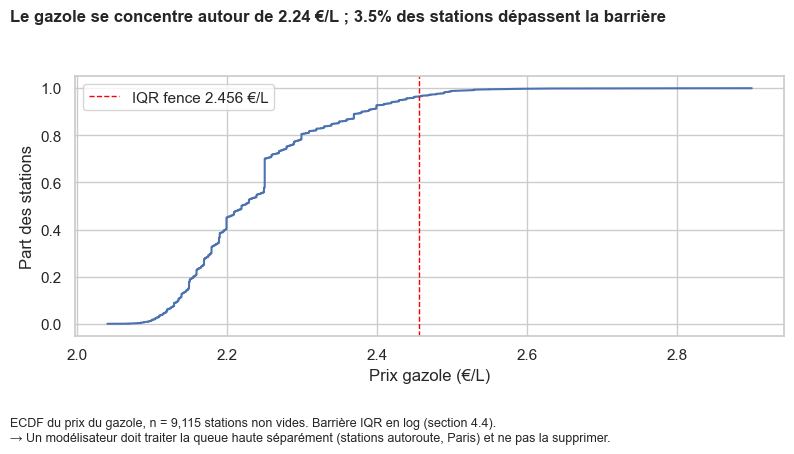

In [26]:
# 5.1 Univariate: distribution of the key variable, prix_gazole (ECDF first, then the numbers)
x = np.sort(df["prix_gazole"].dropna().to_numpy())
ecdf_y = np.arange(1, len(x) + 1) / len(x)
share_above = float((x > hi).mean())     # hi: IQR fence from Section 4.4
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, ecdf_y, lw=1.5)
ax.axvline(hi, color="red", ls="--", lw=1, label=f"IQR fence {hi:.3f} €/L")
ax.set_xlabel("Prix gazole (€/L)"); ax.set_ylabel("Part des stations")
ax.legend()
show(fig,
     f"Le gazole se concentre autour de {x.mean():.2f} €/L ; {share_above:.1%} des stations dépassent la barrière",
     f"ECDF du prix du gazole, n = {len(x):,} stations non vides. Barrière IQR en log (section 4.4).",
     "Un modélisateur doit traiter la queue haute séparément (stations autoroute, Paris) et ne pas la supprimer.",
     "5_1")

### 5.2 Bivariate

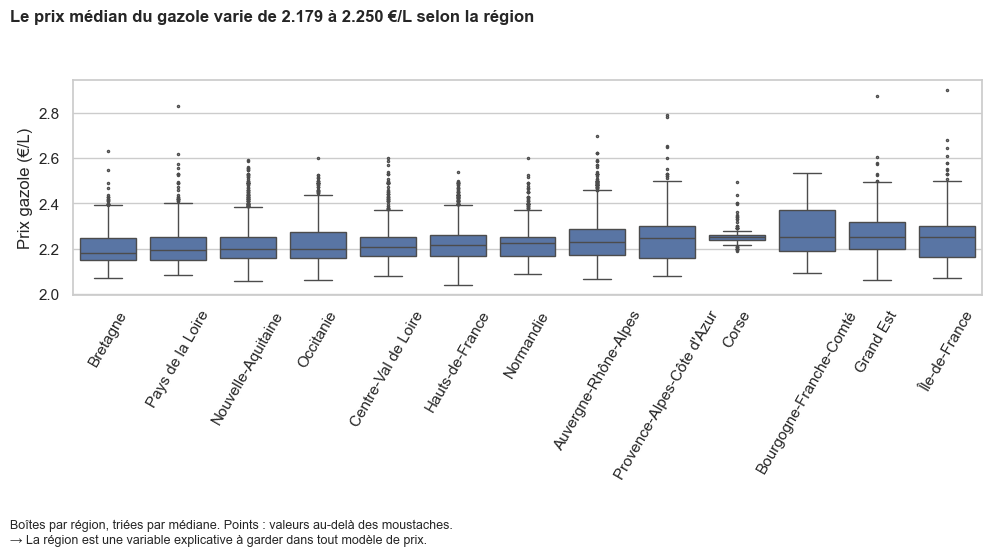

In [27]:
# 5.2 Bivariate: key variable against region (boxplots ordered by median)
order = df.groupby("region")["prix_gazole"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x="region", y="prix_gazole", order=order, ax=ax, fliersize=1.5)
ax.set_xlabel(""); ax.set_ylabel("Prix gazole (€/L)")
ax.tick_params(axis="x", rotation=60)
spread = df.groupby("region")["prix_gazole"].median()
show(fig,
     f"Le prix médian du gazole varie de {spread.min():.3f} à {spread.max():.3f} €/L selon la région",
     "Boîtes par région, triées par médiane. Points : valeurs au-delà des moustaches.",
     "La région est une variable explicative à garder dans tout modèle de prix.",
     "5_2")

### 5.3 Multivariate

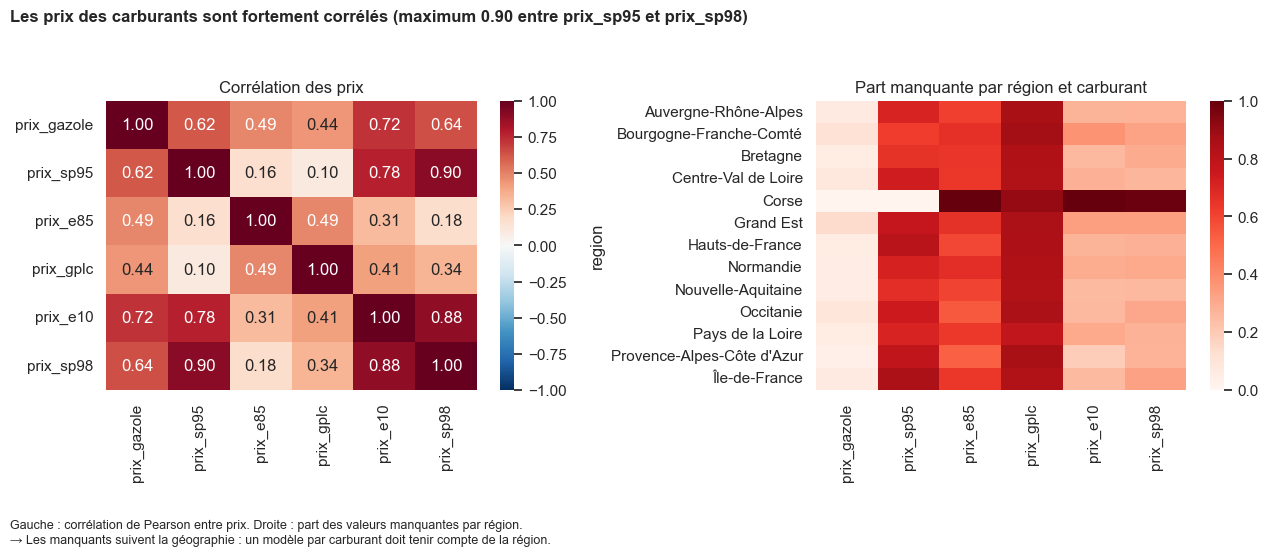

In [28]:
# 5.3 Multivariate: correlation between fuel prices (pairwise, on the rows where both are present)
price_cols = [c for c in df.columns if c.startswith("prix_")]
corr = df[price_cols].corr(min_periods=50)
miss_by_region = df.assign(**{c: df[c].isna() for c in price_cols}).groupby("region")[price_cols].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="RdBu_r", ax=axes[0])
axes[0].set_title("Corrélation des prix")
sns.heatmap(miss_by_region, cmap="Reds", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Part manquante par région et carburant")
top = corr.where(~np.eye(len(corr), dtype=bool)).stack().idxmax()
show(fig,
     f"Les prix des carburants sont fortement corrélés (maximum {corr.loc[top]:.2f} entre {top[0]} et {top[1]})",
     "Gauche : corrélation de Pearson entre prix. Droite : part des valeurs manquantes par région.",
     "Les manquants suivent la géographie : un modèle par carburant doit tenir compte de la région.",
     "5_3")

---
## 6 · Findings, what cannot be trusted, next steps

*TODO*

**Three findings** — each with the figure it comes from and what it means for modelling.
1.
2.
3.

**What cannot be trusted** — column, subset, and why.
-
-

**Five testable hypotheses** — variable, direction, population, test.
- H1:
- H2:
- H3:
- H4:
- H5:

### Final contract & fingerprint
*TODO*: write `clean_schema` for the data a modeller receives (it may differ from the raw schema). Then **Restart & Run All twice**: the fingerprint must be identical.

In [29]:
clean_schema = None                  # TODO: pa.DataFrameSchema({...}, strict=True)
if clean_schema is not None:
    clean_schema.validate(clean, lazy=True)
    print("✅ clean data passes the contract")

clean.to_parquet(DATA / "processed" / "clean.parquet", index=False)
fingerprint = hashlib.sha256(
    pd.util.hash_pandas_object(clean.astype(str), index=False).values.tobytes()).hexdigest()[:12]
print("rows:", len(clean), "· fingerprint:", fingerprint)

rows: 9827 · fingerprint: c0bae3dd8f84


> **Reproducibility note.** The fingerprint is stable between runs *thanks to the cache*: the API data changes over time, so a run without the cache (or after `CACHE_HOURS`) can give a different fingerprint. That is expected — record the collection date in Section 1 and in the README, and commit the raw Parquet if it is small enough.